# Notebook 4: Univariate Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("data.csv", encoding="cp1252")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## Numerical variable analysis
Numerical variables contain values that can be counted or measured. In your dataset, we will focus on Quantity and UnitPrice.
3.1 Mean, median, and mode
- Mean: The average value.
- Median: The middle value after sorting the data.
- Mode: The most frequently occurring value.

In [2]:
column = "Quantity"

print("Mean:", df[column].mean())
print("Median:", df[column].median())

mode_values = df[column].mode()
print("Mode:", mode_values.tolist())

Mean: 9.55224954743324
Median: 3.0
Mode: [1]


### Minimum, maximum, and range
- Minimum: The smallest observed value.
- Maximum: The largest observed value.
- Range: Maximum minus minimum.

In [3]:
for column in ["Quantity", "UnitPrice"]:
    minimum = df[column].min()
    maximum = df[column].max()
    data_range = maximum - minimum

    print(f"\n{column}")
    print("Minimum:", minimum)
    print("Maximum:", maximum)
    print("Range:", data_range)


Quantity
Minimum: -80995
Maximum: 80995
Range: 161990

UnitPrice
Minimum: -11062.06
Maximum: 38970.0
Range: 50032.06


### Variance
- Variance: Measures how spread out values are around the mean.
### standard deviation
- Standard deviation: The square root of the variance, expressed in the same units as the original variable.

In [4]:
for column in ["Quantity", "UnitPrice"]:
    print(f"\n{column}")
    print("Sample variance:", df[column].var())
    print("Sample standard deviation:", df[column].std())


Quantity
Sample variance: 47559.391409298616
Sample standard deviation: 218.08115785023386

UnitPrice
Sample variance: 9362.469164421023
Sample standard deviation: 96.75985306117937


## Quartiles and percentiles
Quartiles divide sorted data into four parts:
- Q1 (25th percentile): 25% of observations are at or below this value.
- Q2 (50th percentile): The median.
- Q3 (75th percentile): 75% of observations are at or below this value.

In [5]:
for column in ["Quantity", "UnitPrice"]:
    print(f"\n--- {column} ---")

    print("Quartiles:")
    print(df[column].quantile([0.25, 0.50, 0.75]))

    print("\nSelected percentiles:")
    print(df[column].quantile([0.01, 0.10, 0.90, 0.95, 0.99]))


--- Quantity ---
Quartiles:
0.25     1.0
0.50     3.0
0.75    10.0
Name: Quantity, dtype: float64

Selected percentiles:
0.01     -2.0
0.10      1.0
0.90     24.0
0.95     29.0
0.99    100.0
Name: Quantity, dtype: float64

--- UnitPrice ---
Quartiles:
0.25    1.25
0.50    2.08
0.75    4.13
Name: UnitPrice, dtype: float64

Selected percentiles:
0.01     0.19
0.10     0.63
0.90     7.95
0.95     9.95
0.99    18.00
Name: UnitPrice, dtype: float64


## Skewness
Skewness describes the asymmetry of a distribution.
- Positive skew: A longer tail toward higher values.
- Negative skew: A longer tail toward lower values.
- Near-zero skew: The distribution may be roughly symmetric, although skewness alone does not prove symmetry.

In [6]:
for column in ["Quantity", "UnitPrice"]:
    print(column, "skewness:", df[column].skew())

Quantity skewness: -0.2640763070669525
UnitPrice skewness: 186.50697172054137


## Kurtosis
Kurtosis describes aspects of the distribution's tails and extreme values relative to a normal distribution.

In [7]:
for column in ["Quantity", "UnitPrice"]:
    print(column, "kurtosis:", df[column].kurt())

Quantity kurtosis: 119769.1600306859
UnitPrice kurtosis: 59005.71909694814


## Histogram
A histogram shows how frequently numerical values fall within intervals called bins.

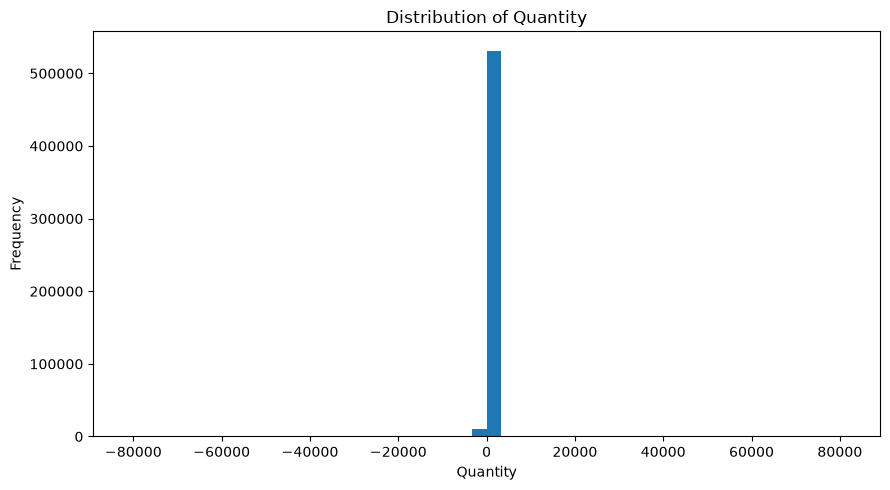

In [8]:
plt.figure(figsize=(9, 5))

plt.hist(df["Quantity"].dropna(), bins=50)

plt.title("Distribution of Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## KDE / density plot
A kernel density estimate (KDE) is a smoothed representation of a numerical distribution.

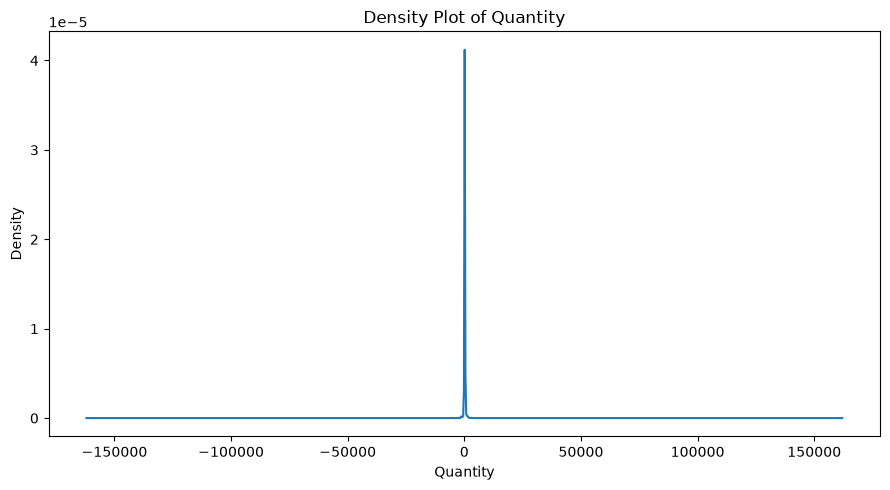

In [9]:
df["Quantity"].dropna().plot(
    kind="kde",
    figsize=(9, 5),
    title="Density Plot of Quantity"
)

plt.xlabel("Quantity")
plt.tight_layout()
plt.show()

## Box plot
A box plot displays the median, quartiles, and potential outliers.

C:\Users\Muges\AppData\Local\Temp\ipykernel_31520\2927151328.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["Quantity"].dropna(), vert=False)


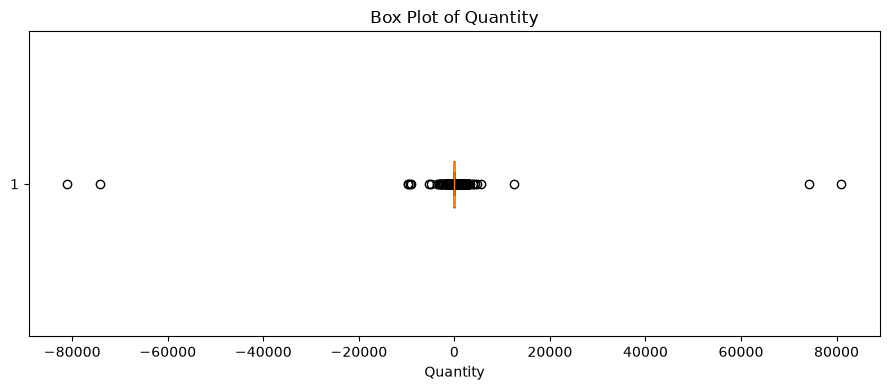

In [10]:
plt.figure(figsize=(9, 4))

plt.boxplot(df["Quantity"].dropna(), vert=False)

plt.title("Box Plot of Quantity")
plt.xlabel("Quantity")
plt.tight_layout()
plt.show()

### Frequency
- Frequency: Number of records belonging to a category.
## unique values
- Unique values: Number of distinct categories.
- Value counts: Frequency of each category.

In [11]:
print("Number of unique countries:", df["Country"].nunique())

print("\nCountry frequencies:")
print(df["Country"].value_counts())

Number of unique countries: 38

Country frequencies:
Country
United Kingdom          495478
Germany                   9495
France                    8557
EIRE                      8196
Spain                     2533
Netherlands               2371
Belgium                   2069
Switzerland               2002
Portugal                  1519
Australia                 1259
Norway                    1086
Italy                      803
Channel Islands            758
Finland                    695
Cyprus                     622
Sweden                     462
Unspecified                446
Austria                    401
Denmark                    389
Japan                      358
Poland                     341
Israel                     297
USA                        291
Hong Kong                  288
Singapore                  229
Iceland                    182
Canada                     151
Greece                     146
Malta                      127
United Arab Emirates        68
European 

## Percentage distribution
Percentage distribution shows what proportion of records belongs to each category.
### Formula:
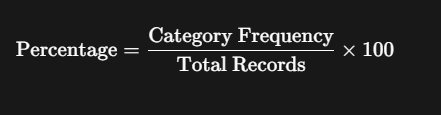

In [12]:
country_counts = df["Country"].value_counts()

country_percentages = (
    df["Country"].value_counts(normalize=True) * 100
)

country_summary = pd.DataFrame({
    "Frequency": country_counts,
    "Percentage": country_percentages.round(2)
})

display(country_summary.head(10))

,Frequency,Percentage
Country,,
United Kingdom,495478,91.43
Germany,9495,1.75
France,8557,1.58
EIRE,8196,1.51
Spain,2533,0.47
Netherlands,2371,0.44
Belgium,2069,0.38
Switzerland,2002,0.37
Portugal,1519,0.28


## Bar chart
A bar chart compares the frequencies of different categories.

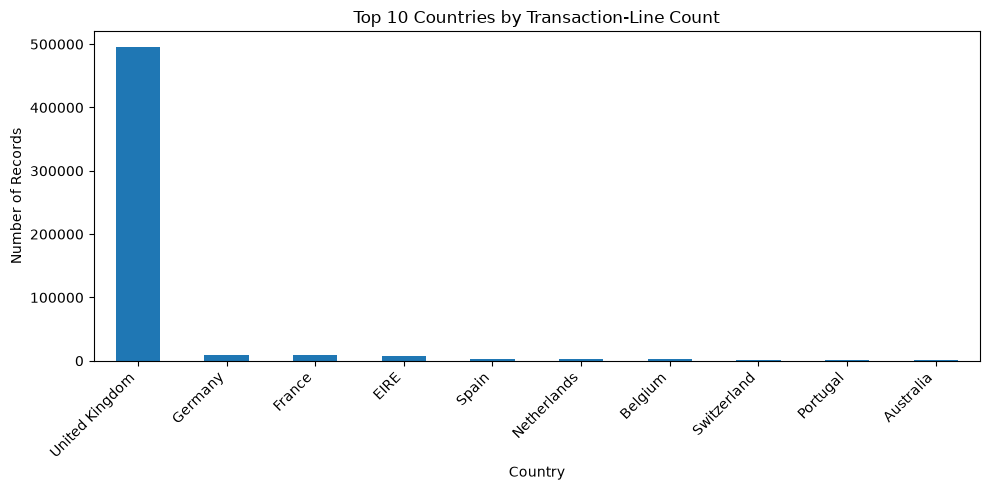

In [13]:
top_countries = df["Country"].value_counts().head(10)

plt.figure(figsize=(10, 5))
top_countries.plot(kind="bar")

plt.title("Top 10 Countries by Transaction-Line Count")
plt.xlabel("Country")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Count plot
A count plot displays the number of observations in each category. Pandas can create the same type of visualization without requiring Seaborn.

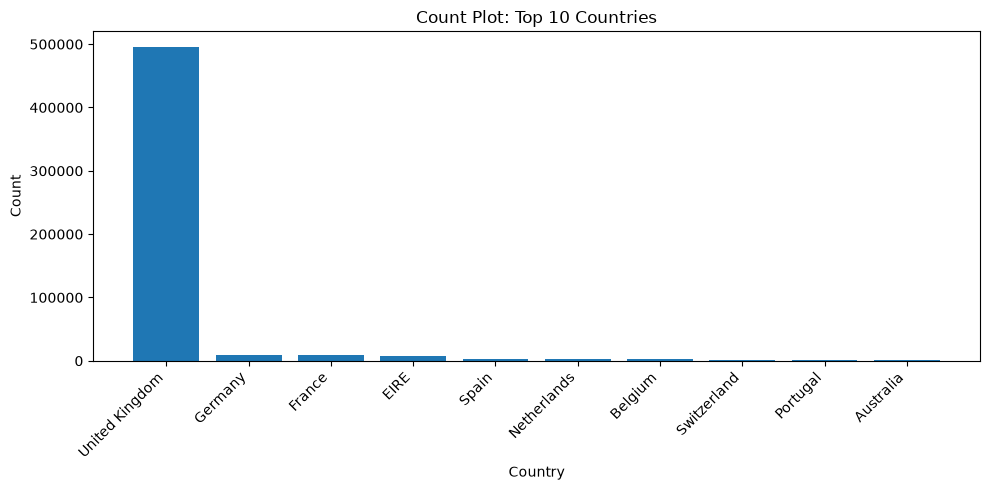

In [14]:
country_counts = df["Country"].value_counts().head(10)

plt.figure(figsize=(10, 5))
plt.bar(country_counts.index, country_counts.values)

plt.title("Count Plot: Top 10 Countries")
plt.xlabel("Country")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Pie chart
A pie chart is useful when showing a small number of categories as proportions of a whole.

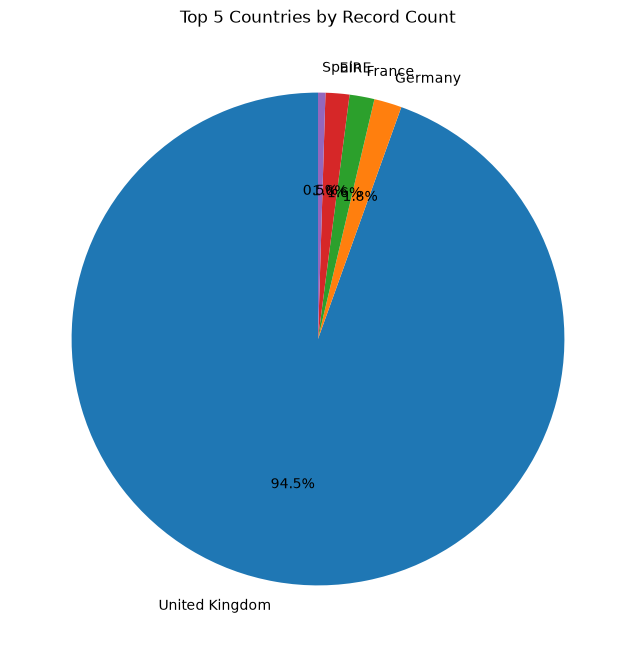

In [16]:
top_countries = df["Country"].value_counts().head(5)

plt.figure(figsize=(8, 8))
plt.pie(
    top_countries.values,
    labels=top_countries.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Top 5 Countries by Record Count")
plt.show()